# What is a Small Language Model?
### From counting words to counting parameters: the core ideas behind SLMs, in runnable Python

> **Learning objective:** Build the simplest possible language model by hand, use it to score and generate text, measure it with perplexity, and then learn how to reason about a model's *size*: parameters, memory and compute. These are the ideas that decide whether a model counts as "small".

This is the first notebook of **Module 00 · Introduction**. It is the hands-on companion to [`intro-to-slms.md`](../intro-to-slms.md).

### What this notebook is (and is not)

- It uses **pure Python, NumPy, Pandas and Matplotlib**. No deep-learning framework yet.
- The language model here is a **count-based bigram model**, not a neural network. It is the clearest way to see what *every* language model, including a Transformer, is trying to do.
- The parameter, memory and compute numbers are **rules of thumb** for reasoning about scale, not precise benchmarks.

### Notebook map

1. A language model is a probability distribution
2. The simplest language model: bigram counts
3. The chain rule: scoring a whole sentence
4. Log-probabilities: why we never multiply raw probabilities
5. Generating text: greedy decoding, sampling and temperature
6. Measuring a language model: cross-entropy and perplexity
7. The limits of counting, and why we need neural networks
8. What is a parameter? Counting the parameters of a GPT
9. What makes a model "small": memory and compute budgets
10. SLM vs LLM: the trade-offs
11. Summary, knowledge check and what comes next

### Imports

All imports live here, at the top of the notebook.

In [2]:
import math
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
pd.set_option("display.precision", 4)

SEED = 42
rng = np.random.default_rng(SEED)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NumPy: 2.4.6
Pandas: 3.1.1

## 1. A language model is a probability distribution

Consider two unfinished sentences:

```text
The capital of India is ______
Artificial intelligence is transforming the way people ______
```

For the first, one answer (*New Delhi*) dominates. For the second, many answers are plausible: *work*, *learn*, *communicate*, *think*...

A language model doesn't store "the right answer". It assigns a **probability to every token in its vocabulary**, given the context:

$$
P(\text{next token} \mid \text{context})
$$

Formally, a **language model** is a model of the probability distribution over sequences of tokens. A **small** language model does the same job with a comparatively compact parameter count and compute footprint. *How* compact is the subject of sections 8 and 9.

Let's build one from scratch.

## 2. The simplest language model: bigram counts

The simplest useful approximation is to predict the next token using **only the previous token**. This is a **bigram** model:

$$
P(x_t \mid x_1, \ldots, x_{t-1}) \;\approx\; P(x_t \mid x_{t-1})
$$

We estimate each probability by counting how often word $b$ follows word $a$ in a training corpus:

$$
P(b \mid a) = \frac{\text{count}(a, b)}{\sum_{w} \text{count}(a, w)}
$$

Our corpus is tiny and deliberately simple. The `.` token marks the end of a sentence, so the model also learns which words tend to *start* a sentence (the words that follow `.`).

In [3]:
corpus = '''
the sun rises in the east .
the sun sets in the west .
the moon rises at night .
the moon shines in the night sky .
the stars shine in the night sky .
the sun shines in the day sky .
birds sing in the morning .
the sun rises in the morning .
the moon sets in the morning .
people work in the day .
people sleep at night .
'''

tokens = corpus.split()
vocab = sorted(set(tokens))

print("Number of tokens:", len(tokens))
print("Vocabulary size: ", len(vocab))
print("Vocabulary:", vocab)

Number of tokens: 75
Vocabulary size:  22
Vocabulary: ['.', 'at', 'birds', 'day', 'east', 'in', 'moon', 'morning', 'night', 'people', 'rises', 'sets', 'shine', 'shines', 'sing', 'sky', 'sleep', 'stars', 'sun', 'the', 'west', 'work']

### Count the bigrams

`bigram_counts[a][b]` stores how many times token `b` appeared directly after token `a`.

In [4]:
bigram_counts = defaultdict(Counter)
for prev, nxt in zip(tokens, tokens[1:]):
    bigram_counts[prev][nxt] += 1


def next_token_distribution(prev):
    # P(next | prev) for every token that has followed `prev` in the corpus.
    counts = bigram_counts[prev]
    total = sum(counts.values())
    return {token: count / total for token, count in counts.most_common()}


for context in ["the", "sun", "at"]:
    dist = next_token_distribution(context)
    pretty = ", ".join(f"{tok}={p:.2f}" for tok, p in dist.items())
    print(f"P(next | {context!r:7}) -> {pretty}")

P(next | 'the'  ) -> sun=0.24, moon=0.18, morning=0.18, night=0.12, day=0.12, east=0.06, west=0.06, stars=0.06
P(next | 'sun'  ) -> rises=0.50, sets=0.25, shines=0.25
P(next | 'at'   ) -> night=1.00

### Visualize one distribution

After `the`, the model has a genuine **distribution** over several continuations, and the probabilities sum to 1.

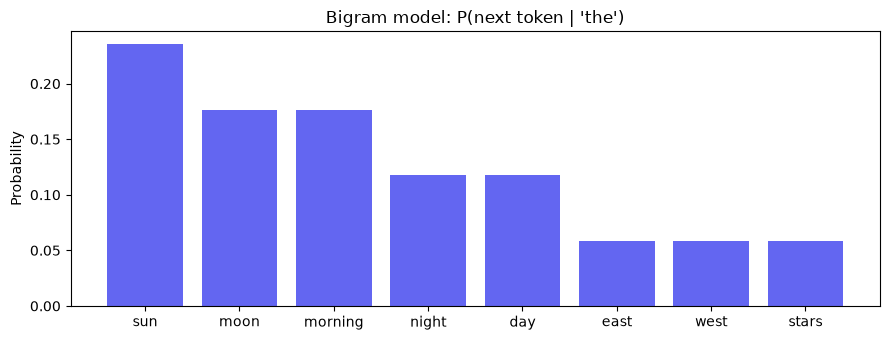

Sum of probabilities: 1.0

In [5]:
dist_the = next_token_distribution("the")

plt.figure(figsize=(9, 3.5))
plt.bar(dist_the.keys(), dist_the.values(), color="#6366f1")
plt.ylabel("Probability")
plt.title("Bigram model: P(next token | 'the')")
plt.tight_layout()
plt.show()

print("Sum of probabilities:", sum(dist_the.values()))

### The full bigram table

We can view the whole model as a $V \times V$ matrix: one row per context token, one column per next token. Every row is a probability distribution.

This matrix *is* the model. Its entries are its "parameters", estimated by counting instead of learned by gradient descent.

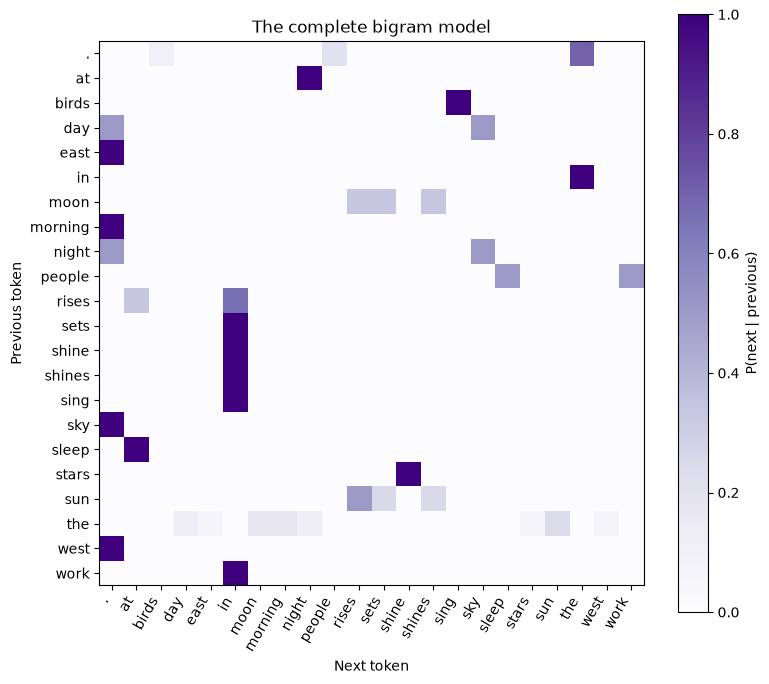

Matrix shape: (22, 22)
Non-zero entries: 39 of 484

In [6]:
V = len(vocab)
token_to_id = {tok: i for i, tok in enumerate(vocab)}

count_matrix = np.zeros((V, V))
for prev, nxts in bigram_counts.items():
    for nxt, c in nxts.items():
        count_matrix[token_to_id[prev], token_to_id[nxt]] = c

prob_matrix = count_matrix / count_matrix.sum(axis=1, keepdims=True)

plt.figure(figsize=(8, 7))
plt.imshow(prob_matrix, cmap="Purples", vmin=0, vmax=1)
plt.colorbar(label="P(next | previous)")
plt.xticks(range(V), vocab, rotation=60, ha="right")
plt.yticks(range(V), vocab)
plt.xlabel("Next token")
plt.ylabel("Previous token")
plt.title("The complete bigram model")
plt.tight_layout()
plt.show()

print("Matrix shape:", prob_matrix.shape)
print("Non-zero entries:", int((prob_matrix > 0).sum()), "of", V * V)

Notice how **sparse** the matrix is: most entries are exactly zero, because most word pairs never appeared. Keep that in mind; it becomes a real problem in sections 6 and 7.

## 3. The chain rule: scoring a whole sentence

By the **chain rule of probability**, the probability of a sequence factorizes into one term per token:

$$
P(x_1, \ldots, x_T) = \prod_{t=1}^{T} P(x_t \mid x_1, \ldots, x_{t-1})
$$

Our bigram model approximates each factor with $P(x_t \mid x_{t-1})$. Below, we score sentences *given that they start with* their first word, so the product begins at the second token.

In [7]:
def sentence_probability(sentence):
    words = sentence.split()
    running = 1.0
    rows = []
    for prev, word in zip(words, words[1:]):
        p = next_token_distribution(prev).get(word, 0.0)
        running *= p
        rows.append((f"P({word} | {prev})", p, running))
    table = pd.DataFrame(rows, columns=["factor", "probability", "running product"])
    return running, table


prob, table = sentence_probability("the sun rises in the east")
display(table)
print(f"P(sentence | starts with 'the') = {prob:.4f}")

,factor,probability,running product
0,P(sun | the),0.2353,0.2353
1,P(rises | sun),0.5000,0.1176
2,P(in | rises),0.6667,0.0784
3,P(the | in),1.0000,0.0784
4,P(east | the),0.0588,0.0046


P(sentence | starts with 'the') = 0.0046

### Three sentences, three lessons

In [8]:
examples = [
    "the sun rises in the east",   # appears in the corpus
    "the moon rises in the east",  # never appears, but every bigram does
    "the east rises in the sun",   # contains a bigram never seen in training
]

for s in examples:
    p, _ = sentence_probability(s)
    print(f"{p:.5f}   {s}")

0.00461   the sun rises in the east
0.00231   the moon rises in the east
0.00000   the east rises in the sun

1. A sentence from the corpus gets a reasonable probability.
2. **`the moon rises in the east` never appears in the corpus**, yet it gets a non-zero probability, because each of its *pairs* was seen. This is a first, tiny taste of **generalization**.
3. `the east rises in the sun` gets probability **exactly zero**, because `east → rises` was never observed. A single unseen pair wipes out the entire sentence. We'll fix this in section 6.

## 4. Log-probabilities: why we never multiply raw probabilities

Every factor in the chain rule is between 0 and 1, so the product shrinks quickly as the sequence gets longer. For realistic sequence lengths, it falls below the smallest number a computer can represent and **underflows to exactly zero**.

The fix is to work with logarithms. The log turns the product into a sum:

$$
\log P(x_1, \ldots, x_T) = \sum_{t=1}^{T} \log P(x_t \mid x_{<t})
$$

In [9]:
per_token_probability = 0.1   # a plausible, even generous, per-token probability
sequence_length = 400         # a short document

direct_product = per_token_probability ** sequence_length
log_sum = sequence_length * math.log(per_token_probability)

print("Direct product:      ", direct_product)
print("Sum of log-probs:    ", round(log_sum, 3))
print("Smallest float64 > 0:", np.nextafter(0, 1))

Direct product:       0.0
Sum of log-probs:     -921.034
Smallest float64 > 0: 5e-324

The direct product is `0.0`, so all the information is gone. The log-probability, about $-921$, is perfectly usable.

This is why every training framework works with **log-probabilities**, and why the standard training loss, *cross-entropy*, is a sum (or mean) of negative log-probabilities.

## 5. Generating text: greedy decoding, sampling and temperature

A language model generates text **autoregressively**:

1. Look at the context.
2. Get a distribution over the next token.
3. Choose a token using a **decoding strategy**.
4. Append it to the context and repeat.

Two basic strategies:

- **Greedy decoding** always picks the most probable token.
- **Sampling** draws a token at random, in proportion to its probability.

**Temperature** $\tau$ reshapes the distribution before sampling. With logits $z_i = \log p_i$:

$$
p_i^{(\tau)} = \frac{\exp(z_i / \tau)}{\sum_j \exp(z_j / \tau)}
$$

$\tau < 1$ sharpens the distribution (safer, more repetitive), and $\tau > 1$ flattens it (more varied, eventually chaotic).

In [10]:
def apply_temperature(probs, temperature):
    logits = np.log(probs) / temperature
    logits -= logits.max()              # numerical stability
    scaled = np.exp(logits)
    return scaled / scaled.sum()


def generate(start, max_tokens=15, strategy="sample", temperature=1.0, rng=None):
    rng = rng if rng is not None else np.random.default_rng(0)
    output = [start]
    for _ in range(max_tokens):
        dist = next_token_distribution(output[-1])
        if not dist:
            break
        candidates = list(dist)
        probs = np.array(list(dist.values()))
        if strategy == "greedy":
            next_token = candidates[int(np.argmax(probs))]
        else:
            probs = apply_temperature(probs, temperature)
            next_token = candidates[rng.choice(len(candidates), p=probs)]
        output.append(next_token)
        if next_token == ".":
            break
    return " ".join(output)


print("Greedy:", generate("the", strategy="greedy"))

Greedy: the sun rises in the sun rises in the sun rises in the sun rises in

### Greedy decoding gets stuck in a loop

`the → sun → rises → in → the → sun → ...`. Each step picks the locally best token, and with a one-token memory the model can't notice it is repeating itself. Repetition is a well-known weakness of greedy decoding, even in large models.

Sampling breaks the loop:

In [11]:
sampling_rng = np.random.default_rng(SEED)
for temperature in (0.3, 1.0, 3.0):
    print(f"--- temperature = {temperature}")
    for _ in range(3):
        print("  ", generate("the", temperature=temperature, rng=sampling_rng))

--- temperature = 0.3
   the morning .
   the morning .
   the sun shines in the sun rises in the moon sets in the moon rises in
--- temperature = 1.0
   the night sky .
   the stars shine in the morning .
   the sun sets in the moon shines in the sun rises in the morning .
--- temperature = 3.0
   the east .
   the west .
   the morning .

### What temperature does to the distribution

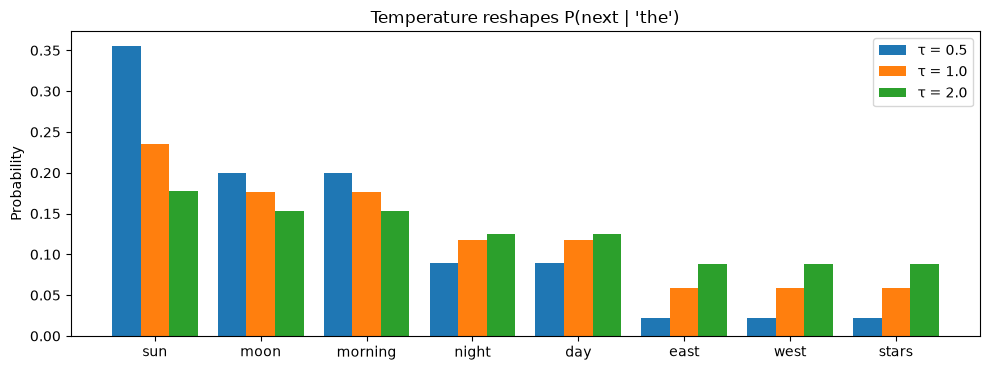

In [12]:
labels = list(dist_the.keys())
base_probs = np.array(list(dist_the.values()))
temperatures = [0.5, 1.0, 2.0]
width = 0.27

plt.figure(figsize=(10, 3.8))
for i, t in enumerate(temperatures):
    plt.bar(np.arange(len(labels)) + (i - 1) * width, apply_temperature(base_probs, t),
            width=width, label=f"τ = {t}")
plt.xticks(range(len(labels)), labels)
plt.ylabel("Probability")
plt.title("Temperature reshapes P(next | 'the')")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Measuring a language model: cross-entropy and perplexity

How good is a language model? We give it text it **has not seen** and measure how much probability it assigns to the tokens that actually occur.

The **average negative log-likelihood** (cross-entropy) over $N$ predicted tokens is:

$$
\mathcal{L} = -\frac{1}{N} \sum_{t=1}^{N} \log P(x_t \mid x_{<t})
$$

**Perplexity** is its exponential:

$$
\text{PPL} = \exp(\mathcal{L})
$$

Perplexity has a friendly interpretation. A perplexity of $k$ means the model is, on average, as uncertain as if it were choosing **uniformly among $k$ tokens**. A model that knows nothing (uniform over the vocabulary) has perplexity exactly $V$. Lower is better.

### Held-out text

These sentences use only words from our vocabulary, but contain **word pairs never seen in training**.

In [13]:
held_out = '''
the stars shine in the night sky .
birds sing at night .
the moon shines in the day sky .
'''
held_out_tokens = held_out.split()

assert set(held_out_tokens) <= set(vocab), "held-out text must use known words"

unseen_pairs = [(a, b) for a, b in zip(held_out_tokens, held_out_tokens[1:])
                if bigram_counts[a][b] == 0]
print("Held-out tokens:", len(held_out_tokens))
print("Bigrams never seen in training:", unseen_pairs)

Held-out tokens: 21
Bigrams never seen in training: [('sing', 'at')]

In [14]:
def cross_entropy(token_list, prob_fn):
    nll = []
    for prev, word in zip(token_list, token_list[1:]):
        p = prob_fn(prev, word)
        nll.append(math.inf if p == 0 else -math.log(p))
    return sum(nll) / len(nll)


def mle_prob(prev, word):
    return next_token_distribution(prev).get(word, 0.0)


def uniform_prob(prev, word):
    return 1 / V


for name, fn in [("uniform", uniform_prob), ("bigram (unsmoothed)", mle_prob)]:
    ce = cross_entropy(held_out_tokens, fn)
    print(f"{name:22} cross-entropy = {ce:6.3f}   perplexity = {math.exp(ce):8.3f}")

uniform                cross-entropy =  3.091   perplexity =   22.000
bigram (unsmoothed)    cross-entropy =    inf   perplexity =      inf

The unsmoothed bigram model gets **infinite perplexity**: one unseen pair (`sing → at`) receives probability zero, and $-\log 0 = \infty$. A model that assigns zero probability to something that can happen is infinitely surprised when it does.

### Fix: add-$k$ smoothing

We pretend every pair was seen $k$ extra times:

$$
P_k(b \mid a) = \frac{\text{count}(a, b) + k}{\sum_w \text{count}(a, w) + kV}
$$

No probability is ever zero. But $k$ is a trade-off: too small and unseen events are still nearly impossible; too large and we drown out what the data told us.

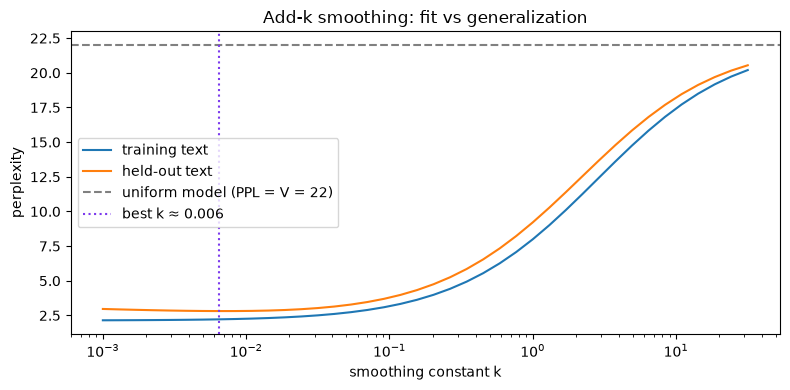

Best held-out perplexity: 2.814 at k = 0.006

In [15]:
def smoothed_prob_fn(k):
    def prob(prev, word):
        counts = bigram_counts[prev]
        return (counts[word] + k) / (sum(counts.values()) + k * V)
    return prob


ks = np.logspace(-3, 1.5, 40)
train_ppl = [math.exp(cross_entropy(tokens, smoothed_prob_fn(k))) for k in ks]
test_ppl = [math.exp(cross_entropy(held_out_tokens, smoothed_prob_fn(k))) for k in ks]
best_k = ks[int(np.argmin(test_ppl))]

plt.figure(figsize=(8, 4))
plt.semilogx(ks, train_ppl, label="training text")
plt.semilogx(ks, test_ppl, label="held-out text")
plt.axhline(V, color="gray", linestyle="--", label=f"uniform model (PPL = V = {V})")
plt.axvline(best_k, color="#7c3aed", linestyle=":", label=f"best k ≈ {best_k:.3f}")
plt.xlabel("smoothing constant k")
plt.ylabel("perplexity")
plt.title("Add-k smoothing: fit vs generalization")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Best held-out perplexity: {min(test_ppl):.3f} at k = {best_k:.3f}")

This small plot contains a lesson that comes back throughout this repository:

- **Training perplexity** is always lowest with almost no smoothing, because the model is just memorizing.
- **Held-out perplexity** is what we actually care about, and it is best at an intermediate setting.

The gap between "fits the training data" and "generalizes to new data" is central to training any language model. In Module 08 we'll track it with training and validation loss.

## 7. The limits of counting, and why we need neural networks

Count-based models have two fundamental problems.

**1. The table explodes.** To condition on the previous $n-1$ tokens, an $n$-gram model needs a table with up to $V^{n}$ entries.

In [16]:
realistic_vocab = 32_000
rows = []
for n in range(1, 6):
    entries = realistic_vocab ** n
    rows.append((f"{n}-gram", f"{n - 1} previous tokens", f"{entries:.2e}"))

display(pd.DataFrame(rows, columns=["model", "context", f"possible entries (V = {realistic_vocab:,})"]))

,model,context,"possible entries (V = 32,000)"
0,1-gram,0 previous tokens,3.20e+04
1,2-gram,1 previous tokens,1.02e+09
2,3-gram,2 previous tokens,3.28e+13
3,4-gram,3 previous tokens,1.05e+18
4,5-gram,4 previous tokens,3.36e+22


A 5-gram model over a 32,000-token vocabulary has about $3.4 \times 10^{22}$ possible entries. Almost none of them will ever be observed, and even this model only sees **4 tokens of context**. A modern SLM attends to thousands.

**2. Nothing is shared between similar words.** In a count table, `sun` and `moon` are completely unrelated rows. Seeing `the sun shines` tells the model nothing about `the moon shines`.

A **neural language model** solves both problems:

- It represents every token as a learned **vector** (an *embedding*), so similar tokens can end up with similar vectors and share statistical strength.
- It computes the next-token distribution with a **fixed number of parameters**, however long the context, instead of a table that grows with it.

The Transformer is the neural network that does this best. We dissect it in the next notebook, [`01_anatomy_of_an_slm.ipynb`](01_anatomy_of_an_slm.ipynb). To understand what makes such a model *small*, we first have to understand its parameters.

## 8. What is a parameter? Counting the parameters of a GPT

A **parameter** is a learnable number inside a neural network. In a linear layer

$$
y = Wx + b, \qquad W \in \mathbb{R}^{d_{out} \times d_{in}}, \; b \in \mathbb{R}^{d_{out}}
$$

there are $d_{in} \cdot d_{out} + d_{out}$ parameters. "A 100-million-parameter model" means a model with about 100 million of these numbers.

In [17]:
def linear_params(d_in, d_out, bias=True):
    return d_in * d_out + (d_out if bias else 0)


print("Linear 512 -> 512:  ", f"{linear_params(512, 512):,}")
print("Linear 512 -> 2048: ", f"{linear_params(512, 2048):,}")
print("Linear 768 -> 50257 (no bias):", f"{linear_params(768, 50257, bias=False):,}")

Linear 512 -> 512:   262,656
Linear 512 -> 2048:  1,050,624
Linear 768 -> 50257 (no bias): 38,597,376

### Where the parameters live in a GPT-style model

A GPT-style decoder (the architecture of GPT-2) has the following parameters:

| Component | Parameters |
|:--|:--|
| Token embedding | $V \cdot d$ |
| Learned position embedding | $T_{max} \cdot d$ |
| Per block, attention: $W_Q, W_K, W_V, W_O$ and biases | $4d^2 + 4d$ |
| Per block, feed-forward: $d \to 4d \to d$ and biases | $8d^2 + 5d$ |
| Per block, two LayerNorms ($\gamma$, $\beta$) | $4d$ |
| Final LayerNorm | $2d$ |
| Output projection | *tied* to the token embedding (0 extra) |

Each block therefore holds $12d^2 + 13d$ parameters, which is roughly $12d^2$.

Rather than trust the formula, let's **list every weight tensor** with its shape and count them independently.

In [18]:
def gpt_weight_shapes(vocab_size, d_model, n_layers, context_length):
    # Every learnable tensor in a GPT-2-style model, as {name: shape}.
    d = d_model
    shapes = {
        "token_embedding": (vocab_size, d),
        "position_embedding": (context_length, d),
    }
    for layer in range(n_layers):
        p = f"block{layer}."
        shapes.update({
            p + "ln1.gamma": (d,), p + "ln1.beta": (d,),
            p + "attn.W_qkv": (d, 3 * d), p + "attn.b_qkv": (3 * d,),
            p + "attn.W_out": (d, d), p + "attn.b_out": (d,),
            p + "ln2.gamma": (d,), p + "ln2.beta": (d,),
            p + "mlp.W_up": (d, 4 * d), p + "mlp.b_up": (4 * d,),
            p + "mlp.W_down": (4 * d, d), p + "mlp.b_down": (d,),
        })
    shapes["final_ln.gamma"] = (d,)
    shapes["final_ln.beta"] = (d,)
    # The output projection reuses token_embedding (weight tying), so it adds nothing.
    return shapes


def count_from_shapes(shapes):
    return sum(int(np.prod(s)) for s in shapes.values())


def gpt_params_formula(vocab_size, d_model, n_layers, context_length):
    d = d_model
    return vocab_size * d + context_length * d + n_layers * (12 * d**2 + 13 * d) + 2 * d


gpt2_small = dict(vocab_size=50_257, d_model=768, n_layers=12, context_length=1024)
print(f"GPT-2 small, from tensor shapes: {count_from_shapes(gpt_weight_shapes(**gpt2_small)):,}")
print(f"GPT-2 small, from the formula:   {gpt_params_formula(**gpt2_small):,}")

GPT-2 small, from tensor shapes: 124,439,808
GPT-2 small, from the formula:   124,439,808

Both methods give **124,439,808** parameters, the published size of GPT-2 small ("124M").

### Compare model configurations

Let's compare a range of configurations, from the toy model in the next notebook up to roughly a billion parameters. Apart from GPT-2 small, these are **illustrative configurations**, not specific released models.

In [19]:
configs = {
    "toy (notebook 01)":   dict(vocab_size=5,      d_model=16,   n_layers=1,  context_length=6),
    "tiny":                dict(vocab_size=8_192,  d_model=256,  n_layers=4,  context_length=512),
    "small":               dict(vocab_size=32_000, d_model=512,  n_layers=8,  context_length=1024),
    "GPT-2 small":         dict(vocab_size=50_257, d_model=768,  n_layers=12, context_length=1024),
    "compact (~1B class)": dict(vocab_size=32_000, d_model=2048, n_layers=18, context_length=2048),
}

rows = []
for name, cfg in configs.items():
    total = gpt_params_formula(**cfg)
    embeddings = (cfg["vocab_size"] + cfg["context_length"]) * cfg["d_model"]
    blocks = cfg["n_layers"] * (12 * cfg["d_model"] ** 2 + 13 * cfg["d_model"])
    rows.append({
        "model": name, **cfg,
        "total params": total,
        "embedding share": embeddings / total,
        "block share": blocks / total,
    })

params_table = pd.DataFrame(rows).set_index("model")
display(params_table.assign(**{
    "total params": params_table["total params"].map("{:,}".format),
    "embedding share": params_table["embedding share"].map("{:.1%}".format),
    "block share": params_table["block share"].map("{:.1%}".format),
}))

,vocab_size,d_model,n_layers,context_length,total params,embedding share,block share
model,,,,,,,
toy (notebook 01),5,16,1,6,"3,488",5.0%,94.0%
tiny,8192,256,4,512,"5,387,776",41.4%,58.6%
small,32000,512,8,1024,"42,128,384",40.1%,59.9%
GPT-2 small,50257,768,12,1024,"124,439,808",31.6%,68.3%
compact (~1B class),32000,2048,18,2048,"976,183,296",7.1%,92.9%


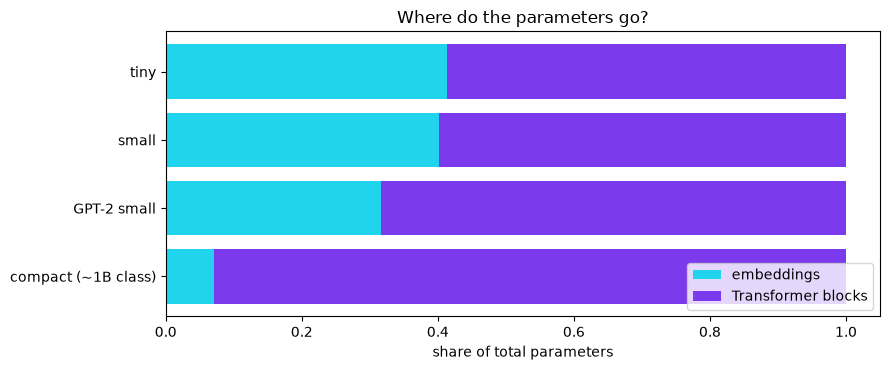

In [20]:
names = params_table.index[1:]   # skip the toy model, it's too small to see
emb = params_table.loc[names, "embedding share"]
blk = params_table.loc[names, "block share"]

plt.figure(figsize=(9, 3.8))
plt.barh(names, emb, color="#22d3ee", label="embeddings")
plt.barh(names, blk, left=emb, color="#7c3aed", label="Transformer blocks")
plt.xlabel("share of total parameters")
plt.title("Where do the parameters go?")
plt.legend(loc="lower right")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

**An important insight for SLMs:** in the "tiny" and "small" configurations, a large share of all parameters sits in the **embedding table**, which is a lookup rather than computation. As models grow, the $12d^2$ block term takes over.

That's why vocabulary size is an important design decision for small models, and why techniques such as **weight tying** (sharing the input embedding with the output projection) matter more at small scale. We return to this in Module 01 (tokenization) and Module 04 (SLM architecture).

## 9. What makes a model "small": memory and compute budgets

Parameter count matters because it drives **memory** and **compute**.

### Memory for the weights

Each parameter is stored in some numeric format:

| Format | Bytes per parameter |
|:--|--:|
| float32 | 4 |
| bfloat16 / float16 | 2 |
| int8 | 1 |
| int4 | 0.5 |

**Training** needs far more than the weights. With the Adam optimizer in standard mixed precision, a common rule of thumb is about **16 bytes per parameter**: weights, gradients, a float32 master copy and two optimizer moment estimates. That's *before* counting activations, which depend on batch size and sequence length.

In [21]:
BYTES = {"float32": 4, "bfloat16": 2, "int8": 1, "int4": 0.5}
TRAIN_BYTES_PER_PARAM = 16   # Adam + mixed precision rule of thumb, excluding activations


def gib(n_bytes):
    return n_bytes / 1024**3


rows = []
for name, cfg in list(configs.items())[1:]:
    n = gpt_params_formula(**cfg)
    row = {"model": name, "params": f"{n / 1e6:,.0f}M"}
    for fmt, b in BYTES.items():
        row[f"inference {fmt}"] = f"{gib(n * b):.2f} GiB"
    row["training (≈16 B/param)"] = f"{gib(n * TRAIN_BYTES_PER_PARAM):.1f} GiB"
    rows.append(row)

display(pd.DataFrame(rows).set_index("model"))

,params,inference float32,inference bfloat16,inference int8,inference int4,training (≈16 B/param)
model,,,,,,
tiny,5M,0.02 GiB,0.01 GiB,0.01 GiB,0.00 GiB,0.1 GiB
small,42M,0.16 GiB,0.08 GiB,0.04 GiB,0.02 GiB,0.6 GiB
GPT-2 small,124M,0.46 GiB,0.23 GiB,0.12 GiB,0.06 GiB,1.9 GiB
compact (~1B class),976M,3.64 GiB,1.82 GiB,0.91 GiB,0.45 GiB,14.5 GiB


### Compute per token

A useful approximation for a model with $N$ parameters (ignoring the attention cost, which grows with context length):

$$
\text{forward pass} \approx 2N \text{ FLOPs per token}, \qquad \text{training} \approx 6N \text{ FLOPs per token}
$$

Each parameter takes part in about one multiply and one add per token on the forward pass. The backward pass costs roughly twice as much again.

So the total training compute for $D$ training tokens is approximately:

$$
C_{\text{train}} \approx 6ND
$$

In [22]:
def training_flops(n_params, n_tokens):
    return 6 * n_params * n_tokens


def days_on_gpu(flops, sustained_tflops):
    return flops / (sustained_tflops * 1e12) / 86_400


# An illustrative consumer-class GPU sustaining 50 TFLOP/s of useful bf16 throughput.
SUSTAINED_TFLOPS = 50

rows = []
for name in ["tiny", "small", "GPT-2 small", "compact (~1B class)"]:
    n = gpt_params_formula(**configs[name])
    tokens_20x = 20 * n   # "about 20 tokens per parameter" compute-optimal rule of thumb
    flops = training_flops(n, tokens_20x)
    rows.append({
        "model": name,
        "params": f"{n / 1e6:,.0f}M",
        "training tokens (20×N)": f"{tokens_20x / 1e9:,.2f}B",
        "training FLOPs": f"{flops:.2e}",
        f"days @ {SUSTAINED_TFLOPS} TFLOP/s": f"{days_on_gpu(flops, SUSTAINED_TFLOPS):,.2f}",
        "inference GFLOPs / token": f"{2 * n / 1e9:.2f}",
    })

display(pd.DataFrame(rows).set_index("model"))

,params,training tokens (20×N),training FLOPs,days @ 50 TFLOP/s,inference GFLOPs / token
model,,,,,
tiny,5M,0.11B,3.48e+15,0.00,0.01
small,42M,0.84B,2.13e+17,0.05,0.08
GPT-2 small,124M,2.49B,1.86e+18,0.43,0.25
compact (~1B class),976M,19.52B,1.14e+20,26.47,1.95


The "≈20 training tokens per parameter" heuristic comes from compute-optimal scaling research (Hoffmann et al., 2022, the "Chinchilla" paper). It answers a specific question: *for a fixed training budget, how should I split it between model size and data?*

Small models often **deliberately break this rule**. Many modern SLMs are trained on far more tokens than 20× their parameter count. Every query a model answers costs inference compute for its entire lifetime, so spending extra compute once during training to get a better *small* model is often worth it.

The table also shows why SLMs are a realistic target for this repository: a model with tens of millions of parameters can be pretrained from scratch on a single GPU, which is impossible for a frontier LLM.

### Visualize the scale

A log-scale view of weight memory at different precisions makes the deployment story concrete. The horizontal lines mark common memory budgets.

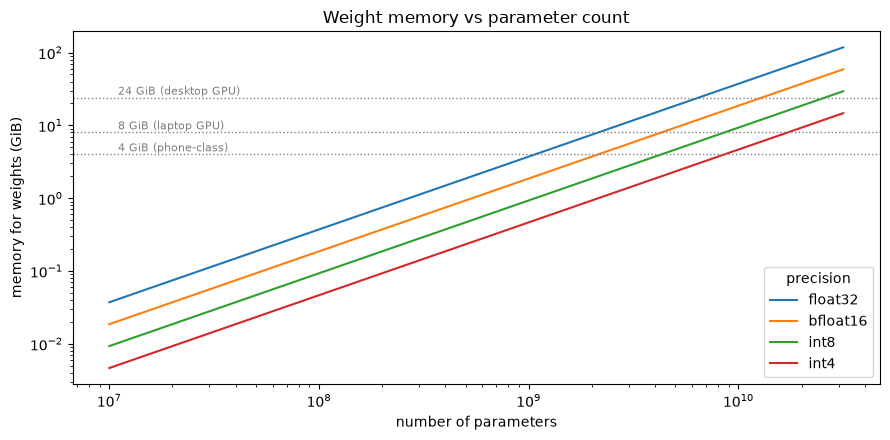

In [23]:
param_counts = np.logspace(7, 10.5, 200)   # 10M to ~30B parameters

plt.figure(figsize=(9, 4.5))
for fmt, b in BYTES.items():
    plt.loglog(param_counts, gib(param_counts * b), label=fmt)

for budget, label in [(4, "4 GiB (phone-class)"), (8, "8 GiB (laptop GPU)"), (24, "24 GiB (desktop GPU)")]:
    plt.axhline(budget, color="gray", linestyle=":", linewidth=1)
    plt.text(param_counts[0] * 1.1, budget * 1.1, label, color="gray", fontsize=8)

plt.xlabel("number of parameters")
plt.ylabel("memory for weights (GiB)")
plt.title("Weight memory vs parameter count")
plt.legend(title="precision")
plt.tight_layout()
plt.show()

## 10. SLM vs LLM: the trade-offs

There is **no official parameter threshold** that makes a model "small". The term is relative, and it moves as hardware improves. What matters is the budget: memory, latency, cost, energy, and where the model has to run.

| Dimension | Small Language Model | Large Language Model |
|:--|:--|:--|
| Parameters | Generally millions to a few billion | Generally tens of billions or more |
| Weight memory | Can fit on a laptop, phone or edge device | Usually needs datacenter GPUs |
| Latency and cost per token | Generally lower | Generally higher |
| Breadth of capability | Often narrower | Often broader |
| Specialization | Can be very strong on a focused task | Strong generalist, can also be specialized |
| Privacy | On-device processing is possible | Typically served remotely |
| Training from scratch | Feasible for individuals and small labs | Requires very large compute budgets |

> **Size isn't quality.** Two models with the same parameter count can perform very differently depending on data quality, the number of training tokens, architecture and optimization. A well-trained small model can beat a larger one on a narrow task.

The goal isn't the smallest possible model. It's a model that delivers **useful capabilities within a practical compute budget**.

## 11. Summary, knowledge check and what comes next

### What we built

- A **bigram language model** estimated by counting, and its full $V \times V$ probability table
- **Sentence scoring** with the chain rule, and the reason we use **log-probabilities**
- **Text generation** with greedy decoding, sampling and temperature
- **Cross-entropy and perplexity** on held-out text, and **add-k smoothing** as a first lesson in generalization
- An exact **parameter counter** for GPT-style models, verified against GPT-2 small (124,439,808)
- **Memory and compute** estimates that tell us what "small" means in practice

### Knowledge check

Try to answer each question before revealing the answer.

<details><summary><b>1. What does a language model output, given a context?</b></summary>

A probability distribution over the entire vocabulary for the next token, not a single answer.
</details>

<details><summary><b>2. Why did "the moon rises in the east" get a non-zero probability even though it never appears in the corpus?</b></summary>

Because the bigram model only needs each adjacent *pair* to have been seen. Combining known pieces into new sequences is a simple form of generalization.
</details>

<details><summary><b>3. Why do we sum log-probabilities instead of multiplying probabilities?</b></summary>

Products of many numbers below 1 underflow to exactly 0.0 in floating point. Sums of logs stay in a comfortable numeric range and are also easier to optimize.
</details>

<details><summary><b>4. Why did greedy decoding repeat itself?</b></summary>

It always picks the single most likely token. With a short memory, it re-enters the same high-probability cycle (`the sun rises in the ...`) and has no randomness to escape.
</details>

<details><summary><b>5. A model has perplexity 20 on held-out text. What does that mean?</b></summary>

On average, it is as uncertain as if it were choosing uniformly among about 20 tokens. A uniform model has perplexity equal to the vocabulary size.
</details>

<details><summary><b>6. Why is training perplexity lowest with almost no smoothing, while held-out perplexity is not?</b></summary>

Without smoothing, the model memorizes the training counts exactly, which scores the training text well but gives near-zero probability to unseen events in new text. Generalization requires giving up a little training fit.
</details>

<details><summary><b>7. Roughly how many parameters does one GPT-style Transformer block have, for hidden size d?</b></summary>

About $12d^2$: $4d^2$ for attention ($W_Q, W_K, W_V, W_O$) and $8d^2$ for the feed-forward network ($d \to 4d \to d$).
</details>

<details><summary><b>8. Why does vocabulary size matter more for small models?</b></summary>

The embedding table has $V \cdot d$ parameters. When $d$ and the number of layers are small, this table can be a large share of the whole model.
</details>

<details><summary><b>9. About how much memory does it take to train a 100M-parameter model with Adam in mixed precision, excluding activations?</b></summary>

Around 16 bytes per parameter, so about 1.6 GB (≈1.5 GiB). Activations come on top and depend on batch size and sequence length.
</details>

### Next notebook

**[`01_anatomy_of_an_slm.ipynb`](01_anatomy_of_an_slm.ipynb): Anatomy of a Small Language Model.**

We replace the count table with a neural network and follow a sentence through every component of a decoder-only Transformer: embeddings, positional encoding, causal self-attention, multi-head attention, feed-forward networks, normalization and the vocabulary projection.